# Preprocessing

This notebook prepares the cleaned visits for a later model. It does not train a model, and it does not change the 15.63% buyer share.

The order is fixed: load, split, then fit any transform on the training rows only.


### A. Load the cleaned table

`read_csv` turns `OperatingSystems`, `Browser`, `Region`, and `TrafficType` back into numbers. They are category codes, so they are cast to text before anything else. The checks confirm the cleaning notebook's result: 12,205 rows and no missing cells.


In [1]:
from pathlib import Path

import numpy as np
import pandas as pd

np.random.seed(42)

if Path("data/processed/cleaned_shoppers.csv").exists():
    processed_dir = Path("data/processed")
    image_dir = Path("images")
    model_dir = Path("models")
else:
    processed_dir = Path("../data/processed")
    image_dir = Path("../images")
    model_dir = Path("../models")

image_dir.mkdir(parents=True, exist_ok=True)
model_dir.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(processed_dir / "cleaned_shoppers.csv")
code_columns = ["OperatingSystems", "Browser", "Region", "TrafficType"]
for column in code_columns:
    df[column] = df[column].astype(str)

assert len(df) == 12205
assert int(df.isna().sum().sum()) == 0
print("Rows:", len(df))
print("Missing cells:", int(df.isna().sum().sum()))
print(df.dtypes.to_string())


Rows: 12205
Missing cells: 0
Administrative               int64
Administrative_Duration    float64
Informational                int64
Informational_Duration     float64
ProductRelated               int64
ProductRelated_Duration    float64
BounceRates                float64
ExitRates                  float64
PageValues                 float64
SpecialDay                 float64
Month                       object
OperatingSystems            object
Browser                     object
Region                      object
TrafficType                 object
VisitorType                 object
Weekend                      int64
Revenue                      int64


### B. Split before any fitting

The rows are split 80/20 before any scaling or encoding. Stratified on `Revenue` means the training part and the test part each keep about the same buyer share. `random_state=42` makes this same split every time the notebook is run.

The files saved here are still the original numbers. Nothing has been scaled yet.


In [2]:
from sklearn.model_selection import train_test_split

feature_columns = [column for column in df.columns if column != "Revenue"]
X = df[feature_columns]
y = df["Revenue"].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y,
)


def report_split(name, y_part):
    buyers = int(y_part.sum())
    print(f"{name}: {len(y_part)} rows, {buyers} buyers, {100 * buyers / len(y_part):.2f}%")


report_split("Train", y_train)
report_split("Test", y_test)

original_columns = df.columns.tolist()
train_clean = X_train.copy()
train_clean["Revenue"] = y_train
test_clean = X_test.copy()
test_clean["Revenue"] = y_test
train_clean = train_clean[original_columns]
test_clean = test_clean[original_columns]

train_path = processed_dir / "train_clean.csv"
test_path = processed_dir / "test_clean.csv"
train_clean.to_csv(train_path, index=False)
test_clean.to_csv(test_path, index=False)
print("Saved", train_path)
print("Saved", test_path)


Train: 9764 rows, 1526 buyers, 15.63%
Test: 2441 rows, 382 buyers, 15.65%
Saved ../data/processed/train_clean.csv
Saved ../data/processed/test_clean.csv


### C. Skew on the training rows only

Skewness says whether a column has a long tail of large values. A skew above 1, with no negative values, gets `log1p` (the log of one plus the value). That choice uses no cutoff learned from the data, so the test rows cannot change it. No row is capped or deleted.

`Weekend` is only 0 or 1. It is left as it is, even if its skew is above 1.


In [3]:
numeric_columns = [
    "Administrative",
    "Administrative_Duration",
    "Informational",
    "Informational_Duration",
    "ProductRelated",
    "ProductRelated_Duration",
    "BounceRates",
    "ExitRates",
    "PageValues",
    "SpecialDay",
    "Weekend",
]

skewness = X_train[numeric_columns].skew().rename("skewness")
minimums = X_train[numeric_columns].min().rename("min")
skew_table = pd.concat([skewness, minimums], axis=1)
print(skew_table.round(4).to_string())

log_columns = [
    column
    for column in numeric_columns
    if column != "Weekend" and skew_table.loc[column, "skewness"] > 1 and skew_table.loc[column, "min"] >= 0
]
scale_columns = [
    column for column in numeric_columns if column not in log_columns and column != "Weekend"
]
print("log1p columns:", log_columns)
print("scale-only columns:", scale_columns)


                         skewness  min
Administrative             1.9861  0.0
Administrative_Duration    5.6769  0.0
Informational              4.0987  0.0
Informational_Duration     7.5427  0.0
ProductRelated             4.3898  0.0
ProductRelated_Duration    7.8719  0.0
BounceRates                3.1730  0.0
ExitRates                  2.2369  0.0
PageValues                 6.5473  0.0
SpecialDay                 3.2690  0.0
Weekend                    1.2573  0.0
log1p columns: ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay']
scale-only columns: []


### Before and after the log

The picture uses three training columns with the longest tails. The top row is the original value. The bottom row is `log1p` of that value. The row count does not change.


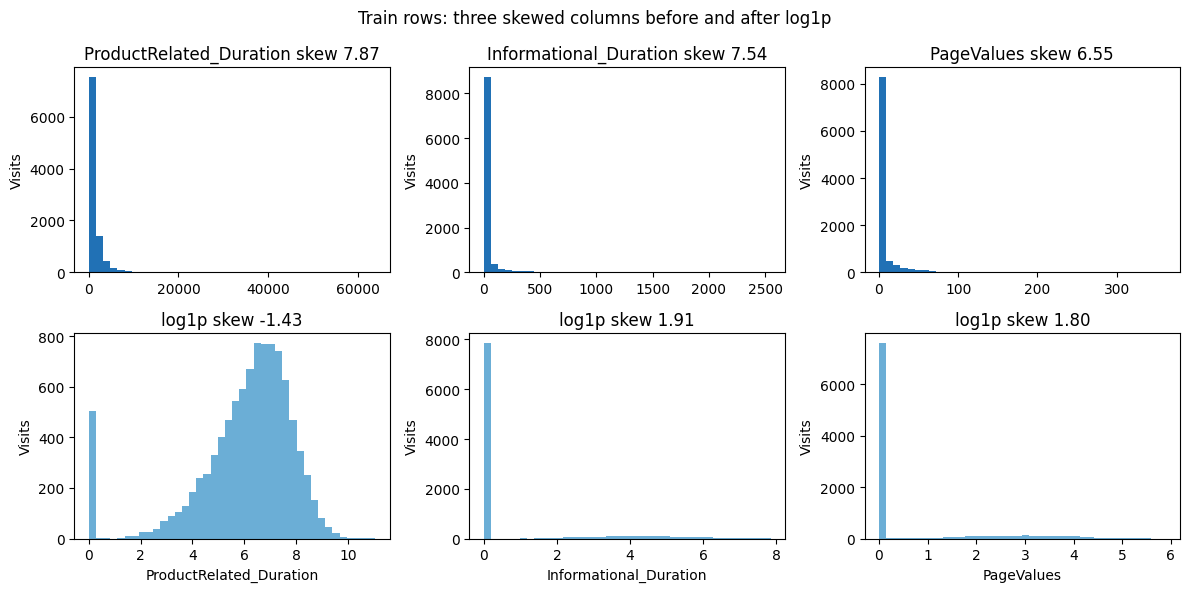

Saved ../images/03_log_before_after.png
ProductRelated_Duration max 63973.52 log1p max 11.07 n 9764
Informational_Duration max 2549.38 log1p max 7.84 n 9764
PageValues max 361.76 log1p max 5.89 n 9764


In [4]:
import matplotlib.pyplot as plt

# Three longest tails among the columns that receive log1p.
picture_columns = list(skew_table.loc[log_columns, "skewness"].sort_values(ascending=False).head(3).index)

fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for index, column in enumerate(picture_columns):
    original = X_train[column]
    logged = np.log1p(original)
    axes[0, index].hist(original, bins=40, color="#2171b5")
    axes[1, index].hist(logged, bins=40, color="#6baed6")
    axes[0, index].set_title(column + " skew " + format(skew_table.loc[column, "skewness"], ".2f"))
    axes[1, index].set_title(f"log1p skew {logged.skew():.2f}")
    axes[0, index].set_ylabel("Visits")
    axes[1, index].set_ylabel("Visits")
    axes[1, index].set_xlabel(column)
fig.suptitle("Train rows: three skewed columns before and after log1p")
fig.tight_layout()
fig.savefig(image_dir / "03_log_before_after.png", dpi=150)
plt.show()
print("Saved", image_dir / "03_log_before_after.png")
for column in picture_columns:
    print(
        column,
        "max",
        round(float(X_train[column].max()), 2),
        "log1p max",
        round(float(np.log1p(X_train[column].max())), 2),
        "n",
        len(X_train),
    )


On the **9,764** training rows, the three longest tails are `ProductRelated_Duration` (skew **7.87**, max **63,973.52**, after log1p the max is **11.07**), `Informational_Duration` (skew **7.54**, max **2,549.38**, after log1p **7.84**), and `PageValues` (skew **6.55**, max **361.76**, after log1p **5.89**). The log changes the shape. It does not drop any of the 9,764 rows.


### Skew before and after log1p

These numbers are the skewness of the logged columns on the 9,764 training rows. The pipeline is unchanged.

`log1p` pulled the long tail down on these columns:

- `Administrative`: 1.9861 before, 0.5578 after
- `Administrative_Duration`: 5.6769 before, 0.2397 after
- `Informational`: 4.0987 before, 2.0128 after
- `Informational_Duration`: 7.5427 before, 1.9131 after
- `ProductRelated`: 4.3898 before, -0.0434 after
- `ProductRelated_Duration`: 7.8719 before, -1.4311 after
- `PageValues`: 6.5473 before, 1.7970 after

`log1p` barely changed these columns:

- `BounceRates`: 3.1730 before, 3.0893 after (change -0.0837)
- `ExitRates`: 2.2369 before, 2.1320 after (change -0.1049)
- `SpecialDay`: 3.2690 before, 3.0868 after (change -0.1821)


### D. One transformer, fit on training rows only

Every input column is kept. `PageValues`, `BounceRates`, and `ExitRates` stay in. Phase 2 decides whether a model should use them.

- A skewed column gets `log1p`, then `StandardScaler` (subtract the training mean, divide by the training spread).
- Any other numeric column gets `StandardScaler` only.
- `Weekend` passes through as 0 or 1.
- `Month`, `VisitorType`, `OperatingSystems`, `Browser`, `Region`, and `TrafficType` are categories. `Month` is a name of a season, not a quantity, so it is not scaled like a number. The encoder turns each category into 0/1 columns. A category with fewer than 20 training rows is grouped as rare. An unseen test category joins that same rare group (`handle_unknown="infrequent_if_exist"`).

Every numeric column except `Weekend` has skew above 1 and a minimum of 0 on the training rows, so each one gets `log1p` and then scaling. That includes the rates and `SpecialDay`: `BounceRates` skew **3.17**, `ExitRates` **2.24**, `PageValues` **6.55**, `SpecialDay` **3.27**. The scale-only list is empty. `Weekend` skew is **1.26**, and it still passes through as 0 or 1 because it is already a yes/no flag.


In [5]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

category_columns = [
    "Month",
    "VisitorType",
    "OperatingSystems",
    "Browser",
    "Region",
    "TrafficType",
]

log_pipe = Pipeline(
    steps=[
        ("log1p", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
        ("scale", StandardScaler()),
    ]
)

transformers = [
    ("log_scale", log_pipe, log_columns),
]
if scale_columns:
    transformers.append(("scale", StandardScaler(), scale_columns))
transformers.append(("weekend", "passthrough", ["Weekend"]))
transformers.append(
    (
        "category",
        OneHotEncoder(
            min_frequency=20,
            handle_unknown="infrequent_if_exist",
            sparse_output=False,
        ),
        category_columns,
    )
)

preprocessor = ColumnTransformer(transformers=transformers, remainder="drop")

# Fit uses training rows only. The test rows are not passed to fit.
preprocessor.fit(X_train)

X_train_processed = preprocessor.transform(X_train)
X_test_processed = preprocessor.transform(X_test)
feature_names = preprocessor.get_feature_names_out()
print("Train shape:", X_train_processed.shape)
print("Test shape:", X_test_processed.shape)
print("Feature count:", len(feature_names))

encoder = preprocessor.named_transformers_["category"]
print("Rare categories grouped from training counts:")
for column, infrequent in zip(category_columns, encoder.infrequent_categories_):
    counts = X_train[column].value_counts()
    if infrequent is None or len(infrequent) == 0:
        print(f"  {column}: none")
        continue
    rare = sorted(list(infrequent), key=lambda value: (int(counts.get(value, 0)), str(value)))
    for value in rare:
        print(f"  {column} {value}: {int(counts[value])} training rows")


Train shape: (9764, 65)
Test shape: (2441, 65)
Feature count: 65
Rare categories grouped from training counts:
  Month: none
  VisitorType: none
  OperatingSystems 5: 5 training rows
  OperatingSystems 7: 6 training rows
  OperatingSystems 6: 12 training rows
  Browser 9: 1 training rows
  Browser 11: 5 training rows
  Browser 12: 8 training rows
  Region: none
  TrafficType 17: 1 training rows
  TrafficType 16: 2 training rows
  TrafficType 18: 9 training rows
  TrafficType 14: 11 training rows
  TrafficType 19: 14 training rows


### E. Checks

The scaled training columns should sit near mean 0 and spread 1, because the scaler was fit on those rows. The test means should not be exactly 0, because those rows did not decide the mean. One-hot columns and `Weekend` are not scaled, so they are left out of this mean check.


In [6]:
assert not np.isnan(X_train_processed).any()
assert not np.isnan(X_test_processed).any()
assert X_train_processed.shape[1] == X_test_processed.shape[1]

n_scaled = len(log_columns) + len(scale_columns)
train_scaled = X_train_processed[:, :n_scaled]
test_scaled = X_test_processed[:, :n_scaled]
train_means = train_scaled.mean(axis=0)
train_stds = train_scaled.std(axis=0)
test_means = test_scaled.mean(axis=0)
test_stds = test_scaled.std(axis=0)

mean_table = pd.DataFrame(
    {
        "train_mean": train_means,
        "train_std": train_stds,
        "test_mean": test_means,
        "test_std": test_stds,
    },
    index=list(log_columns) + list(scale_columns),
)
print(mean_table.round(6).to_string())

assert np.allclose(train_means, 0, atol=1e-6)
assert np.allclose(train_stds, 1, atol=1e-6)
assert not np.allclose(test_means, 0, atol=1e-6)
print("Asserts passed: no missing values, same column count, train mean near 0, train std near 1, test means are not 0.")


                         train_mean  train_std  test_mean  test_std
Administrative                 -0.0        1.0  -0.000145  0.996500
Administrative_Duration         0.0        1.0  -0.001630  0.994399
Informational                  -0.0        1.0  -0.004924  0.993701
Informational_Duration         -0.0        1.0   0.012309  1.012251
ProductRelated                  0.0        1.0   0.004453  0.984891
ProductRelated_Duration         0.0        1.0  -0.010252  1.002828
BounceRates                    -0.0        1.0   0.008704  1.002994
ExitRates                       0.0        1.0  -0.000447  1.002044
PageValues                     -0.0        1.0   0.005581  1.010385
SpecialDay                      0.0        1.0  -0.011480  0.989840
Asserts passed: no missing values, same column count, train mean near 0, train std near 1, test means are not 0.


### F. Save the fitted transformer and the column order

`models/preprocessor.joblib` is the transformer after `fit` on the training rows. `models/feature_names.json` is the output column order from `get_feature_names_out`. Reloading the file and transforming the same 5 test rows must match.


In [7]:
import json

import joblib

joblib_path = model_dir / "preprocessor.joblib"
names_path = model_dir / "feature_names.json"
joblib.dump(preprocessor, joblib_path)
names_path.write_text(json.dumps(list(feature_names), indent=2) + chr(10))
print("Saved", joblib_path)
print("Saved", names_path)
print("Feature names:", len(feature_names))

loaded = joblib.load(joblib_path)
sample = X_test.iloc[:5]
from_memory = preprocessor.transform(sample)
from_disk = loaded.transform(sample)
assert np.allclose(from_memory, from_disk)
print("Reload check passed on 5 test rows.")


Saved ../models/preprocessor.joblib
Saved ../models/feature_names.json
Feature names: 65
Reload check passed on 5 test rows.


### Save the processed rows and the input schema

The processed files are the numbers the transformer produced. `y_train.csv` and `y_test.csv` are the buyer flag, still unbalanced.

`input_schema.json` describes each raw input from the training rows only: its type, its min, max, and median or its allowed values, and which step it goes through. `calculated_from_visit` is true for `PageValues`, `BounceRates`, and `ExitRates` because those three are computed from the visit. This file does not decide whether any column leaks.


In [8]:
train_frame = pd.DataFrame(X_train_processed, columns=feature_names)
test_frame = pd.DataFrame(X_test_processed, columns=feature_names)
train_frame.to_csv(processed_dir / "X_train_processed.csv", index=False)
test_frame.to_csv(processed_dir / "X_test_processed.csv", index=False)
y_train.to_frame("Revenue").to_csv(processed_dir / "y_train.csv", index=False)
y_test.to_frame("Revenue").to_csv(processed_dir / "y_test.csv", index=False)

schema = {}
calculated = {"PageValues", "BounceRates", "ExitRates"}
for column in feature_columns:
    info = {"calculated_from_visit": column in calculated}
    if column in category_columns:
        info["type"] = "category"
        values = X_train[column].astype(str).unique().tolist()
        if column == "Month":
            month_order = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
            info["allowed_values"] = [month for month in month_order if month in values]
        else:
            info["allowed_values"] = sorted(values, key=lambda value: int(value) if str(value).isdigit() else str(value))
        info["preprocessing"] = "OneHotEncoder(min_frequency=20, handle_unknown=infrequent_if_exist)"
    elif column == "Weekend":
        info["type"] = "numeric"
        info["min"] = float(X_train[column].min())
        info["max"] = float(X_train[column].max())
        info["median"] = float(X_train[column].median())
        info["preprocessing"] = "passthrough"
    elif column in log_columns:
        info["type"] = "numeric"
        info["min"] = float(X_train[column].min())
        info["max"] = float(X_train[column].max())
        info["median"] = float(X_train[column].median())
        info["preprocessing"] = "log1p, then StandardScaler"
    else:
        info["type"] = "numeric"
        info["min"] = float(X_train[column].min())
        info["max"] = float(X_train[column].max())
        info["median"] = float(X_train[column].median())
        info["preprocessing"] = "StandardScaler"
    schema[column] = info

schema_path = processed_dir / "input_schema.json"
schema_path.write_text(json.dumps(schema, indent=2) + chr(10))
print("Saved processed tables and", schema_path)
print("Schema columns:", len(schema))

gitignore = Path(".gitignore") if Path(".gitignore").exists() else Path("../.gitignore")
gitignore_text = gitignore.read_text()
print(gitignore_text)
assert ".joblib" not in gitignore_text
assert ".json" not in gitignore_text
print("gitignore does not hide .joblib or .json files.")


Saved processed tables and ../data/processed/input_schema.json
Schema columns: 17
# Jupyter notebook autosave folders
.ipynb_checkpoints/
*/.ipynb_checkpoints/

# Python cache
__pycache__/
*.pyc

# macOS folder metadata
.DS_Store

# Local virtual environment
.venv/
venv/

gitignore does not hide .joblib or .json files.


### G. Library versions

`models/preprocessor.joblib` stores a scikit-learn object. A joblib file only loads safely with the same scikit-learn version that created it. `requirements.txt` pins scikit-learn and joblib to the versions printed below.


In [9]:
import sklearn
import joblib

print("scikit-learn", sklearn.__version__)
print("joblib", joblib.__version__)
requirements_path = Path("requirements.txt") if Path("requirements.txt").exists() else Path("../requirements.txt")
requirements = requirements_path.read_text()
assert f"scikit-learn=={sklearn.__version__}" in requirements
assert f"joblib=={joblib.__version__}" in requirements
print("requirements.txt matches the installed scikit-learn and joblib.")


scikit-learn 1.7.2
joblib 1.6.0
requirements.txt matches the installed scikit-learn and joblib.
